# Classificação e agrupamento de níveis de obesidade
#### Filipe Cruz Siqueira, Giovana Silverio Pereira, Laura Carolini de Souza Saia, Matheus Alcântara Pereira, Thiago Luiz de Matos

## 1. Preparação dos dados e discretização de idade e peso

In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544)

# data (as pandas dataframes)
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets

# metadata
print(estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.metadata)

# variable information
print(estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.variables)


{'uci_id': 544, 'name': 'Estimation of Obesity Levels Based On Eating Habits and Physical Condition ', 'repository_url': 'https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition', 'data_url': 'https://archive.ics.uci.edu/static/public/544/data.csv', 'abstract': 'This dataset include data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition. ', 'area': 'Health and Medicine', 'tasks': ['Classification', 'Regression', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 2111, 'num_features': 16, 'feature_types': ['Integer'], 'demographics': ['Gender', 'Age'], 'target_col': ['NObeyesdad'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2019, 'last_updated': 'Tue Sep 10 2024', 'dataset_doi': '10.24432/C5H31Z', 'creators': [], 'intro_paper': {'ID': 358, 'type': 

### 1.1 Carregamento e descrição do conjunto de dados

In [42]:
import pandas as pd

df = X.join(y)
display(df.head())

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
df_modificado = df.copy()

### 1.2 Discretização de `Age` e `Weight`

In [ ]:
# Faixas de idade: 18 e 30 entram na faixa que começa nesse valor.
df_modificado["Age"] = pd.cut(
    df["Age"],
    bins=[float("-inf"), 18, 31, float("inf")],
    labels=["Menor de 18", "18 a menos de 30", "31 ou mais"],
    right=False,
)

In [6]:
# Faixas de peso: 60 kg entra em Leve e 80 kg entra em Normal.
df_modificado["Weight"] = pd.cut(
    df["Weight"],
    bins=[float("-inf"), 60, 80, float("inf")],
    labels=["Leve", "Normal", "Pesado"],
    right=True,
)

In [7]:
# Mostra os valores antes e depois, lado a lado.
comparacao = pd.DataFrame({
    "Idade original": df["Age"],
    "Faixa de idade": df_modificado["Age"],
    "Peso original": df["Weight"],
    "Faixa de peso": df_modificado["Weight"],
})

display(comparacao.head(10))

,Idade original,Faixa de idade,Peso original,Faixa de peso
0,21.0,18 a 30,64.0,Normal
1,21.0,18 a 30,56.0,Leve
2,23.0,18 a 30,77.0,Normal
3,27.0,18 a 30,87.0,Pesado
4,22.0,18 a 30,89.8,Pesado
5,29.0,18 a 30,53.0,Leve
6,23.0,18 a 30,55.0,Leve
7,22.0,18 a 30,53.0,Leve
8,24.0,18 a 30,64.0,Normal
9,22.0,18 a 30,68.0,Normal


### 1.3 Divisão em conjuntos de treino e teste

In [8]:
from sklearn.model_selection import train_test_split

alvo = "NObeyesdad"

X_original = df.drop(columns=alvo)
X_modificado = df_modificado.drop(columns=alvo)
y = df[alvo]

(
    X_original_treino, X_original_teste,
    X_modificado_treino, X_modificado_teste,
    y_treino, y_teste,
) = train_test_split(
    X_original,
    X_modificado,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [9]:
for coluna in ["Age", "Weight"]:
    print(f"\nFaixas de {coluna}")
    print(df_modificado[coluna].value_counts(dropna=False, sort=False))

print("\nRegistros no treino:", len(y_treino))
print("Registros no teste:", len(y_teste))

assert df_modificado[["Age", "Weight"]].notna().all().all()
assert X_original_treino.index.equals(X_modificado_treino.index)
assert X_original_teste.index.equals(X_modificado_teste.index)


Faixas de Age
Age
Menor de 18     113
18 a 30        1699
31 ou mais      299
Name: count, dtype: int64

Faixas de Weight
Weight
Leve       420
Normal     525
Pesado    1166
Name: count, dtype: int64

Registros no treino: 1688
Registros no teste: 423


## 2. Classificação com Floresta Aleatória

### 2.1 Preparação dos dados


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Prepara os dados transformando atributos de texto em numericos
def preparar(X_treino, X_teste):
    colunas_cat = X_treino.select_dtypes(exclude="number").columns.tolist()

    codificador = ColumnTransformer(
        transformers=[
            ("onehot",
             OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             colunas_cat),
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_treino_enc = codificador.fit_transform(X_treino)  # aprende só no treino
    X_teste_enc = codificador.transform(X_teste)        # só aplica no teste
    return X_treino_enc, X_teste_enc, codificador


X_original_treino_enc, X_original_teste_enc, cod_original = preparar(
    X_original_treino, X_original_teste
)
X_modificado_treino_enc, X_modificado_teste_enc, cod_modificado = preparar(
    X_modificado_treino, X_modificado_teste
)


Verificações e Comparações após a preparação dos dados:

In [11]:
# Diferença de colunas após uso do OneHotEnconder
print("Modificada: de", X_modificado_treino.shape[1], "para", X_modificado_treino_enc.shape[1], "colunas")

Modificada: de 16 para 35 colunas


In [12]:
# Exposição dos dados antes de depois da codificação
display(X_modificado_treino.head(3))
display(X_modificado_treino_enc.head(3))

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
459,Male,18 a 30,1.76,Normal,yes,yes,2.0,3.0,Frequently,no,3.0,no,1.0,2.0,Frequently,Public_Transportation
426,Male,18 a 30,1.75,Normal,no,no,2.0,3.0,Sometimes,no,3.0,no,1.0,1.0,no,Public_Transportation
326,Male,18 a 30,1.70,Leve,yes,yes,3.0,3.0,Sometimes,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation


,Gender_Female,Gender_Male,Age_18 a 30,Age_31 ou mais,Age_Menor de 18,Weight_Leve,Weight_Normal,Weight_Pesado,family_history_with_overweight_no,family_history_with_overweight_yes,...,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,Height,FCVC,NCP,CH2O,FAF,TUE
459,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.76,2.0,3.0,3.0,1.0,2.0
426,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.75,2.0,3.0,3.0,1.0,1.0
326,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.70,3.0,3.0,2.0,3.0,0.0


### 2.2 Treinamento e testes de parâmetros


#### Parâmetros da Floresta Aleatória

- **`n_estimators`** — Número de árvores da floresta. Foram testadas 10, 50, 100 e 200 árvores.
- **`max_depth`** — Profundidade máxima de cada árvore. Foram testados 3, 5, 10 e `None`. Com `None`, esse parâmetro não impõe um limite de profundidade.
- **`random_state=42`** — Fixa a semente usada nas operações aleatórias do modelo para reproduzir os experimentos.
- **`n_jobs=-1`** — Usa os núcleos de processamento disponíveis para paralelizar o treinamento das árvores.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

bases = {
    "Original": (X_original_treino_enc, X_original_teste_enc),
    "Modificada": (X_modificado_treino_enc, X_modificado_teste_enc),
}

valores_n_estimators = [10, 50, 100, 200]
valores_max_depth = [3, 5, 10, None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = []
parametros = {}

for nome_base, (X_tr, X_te) in bases.items():
    for n in valores_n_estimators:
        for prof in valores_max_depth:
            config = f"n_estimators={n}, max_depth={prof}"
            parametros[(nome_base, config)] = {"n_estimators": n, "max_depth": prof}

            rf = RandomForestClassifier(
                n_estimators=n, max_depth=prof, random_state=42, n_jobs=-1
            )
            f1_cv = cross_val_score(rf, X_tr, y_treino, cv=cv, scoring="f1_macro").mean()

            rf.fit(X_tr, y_treino)
            pred_teste = rf.predict(X_te)

            resultados.append({
                "Base": nome_base,
                "Configuração": config,
                "F1 macro (CV treino)": f1_cv,
                "Acurácia treino": rf.score(X_tr, y_treino),
                "Acurácia teste": accuracy_score(y_teste, pred_teste),
                "F1 macro teste": f1_score(y_teste, pred_teste, average="macro"),
            })

resultados = pd.DataFrame(resultados)

In [14]:
# Ordem original dos testes
ordem = resultados.loc[resultados["Base"] == "Original", "Configuração"]

# Reorganiza a tabela: cada configuração vira uma linha e cada base vira uma coluna
comparacao = (
    resultados.pivot(index="Configuração", columns="Base", values="F1 macro teste")
    .loc[ordem]
)
comparacao["Diferença (Modificada − Original)"] = comparacao["Modificada"] - comparacao["Original"]

display(comparacao.round(4))

Base,Modificada,Original,Diferença (Modificada − Original)
Configuração,,,
"n_estimators=10, max_depth=3",0.5485,0.6466,-0.0981
"n_estimators=10, max_depth=5",0.7082,0.7468,-0.0385
"n_estimators=10, max_depth=10",0.8340,0.8889,-0.0549
"n_estimators=10, max_depth=None",0.8582,0.9190,-0.0608
"n_estimators=50, max_depth=3",0.5840,0.6675,-0.0835
"n_estimators=50, max_depth=5",0.7072,0.8215,-0.1144
"n_estimators=50, max_depth=10",0.8591,0.9306,-0.0715
"n_estimators=50, max_depth=None",0.8831,0.9389,-0.0558
"n_estimators=100, max_depth=3",0.5738,0.6655,-0.0917


In [15]:
# Treina o modelo final de cada base
modelos_finais = {}
for nome_base, (X_tr, X_te) in bases.items():
    sub = resultados[resultados["Base"] == nome_base]
    melhor = sub.loc[sub["F1 macro (CV treino)"].idxmax(), "Configuração"]

    modelos_finais[nome_base] = RandomForestClassifier(
        **parametros[(nome_base, melhor)], random_state=42, n_jobs=-1
    ).fit(X_tr, y_treino)

    print(f"{nome_base} - melhor configuração: {melhor}")

Original - melhor configuração: n_estimators=100, max_depth=None
Modificada - melhor configuração: n_estimators=100, max_depth=None


In [16]:
display(
    resultados.sort_values(["Base", "F1 macro (CV treino)"], ascending=[True, False])
    .groupby("Base").head(5).round(4)
)

,Base,Configuração,F1 macro (CV treino),Acurácia treino,Acurácia teste,F1 macro teste
27,Modificada,"n_estimators=100, max_depth=None",0.8847,1.0000,0.8889,0.8882
31,Modificada,"n_estimators=200, max_depth=None",0.8833,1.0000,0.8865,0.8855
23,Modificada,"n_estimators=50, max_depth=None",0.8785,1.0000,0.8842,0.8831
26,Modificada,"n_estimators=100, max_depth=10",0.8678,0.9639,0.8700,0.8692
30,Modificada,"n_estimators=200, max_depth=10",0.8647,0.9668,0.8723,0.8715
11,Original,"n_estimators=100, max_depth=None",0.9375,1.0000,0.9362,0.9362
15,Original,"n_estimators=200, max_depth=None",0.9363,1.0000,0.9409,0.9408
7,Original,"n_estimators=50, max_depth=None",0.9344,1.0000,0.9385,0.9389
14,Original,"n_estimators=200, max_depth=10",0.9282,0.9988,0.9385,0.9380
10,Original,"n_estimators=100, max_depth=10",0.9223,0.9982,0.9291,0.9289


### 2.3 Avaliação dos resultados


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

ordem_classes = [
    "Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
    "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
assert set(ordem_classes) == set(y_teste.unique()), "Ajuste os nomes das classes em ordem_classes"

# Previsões de cada modelo final no conjunto de teste
previsoes = {nome: modelos_finais[nome].predict(X_te) for nome, (X_tr, X_te) in bases.items()}

#### Relatório de classificação

In [18]:
for nome, y_pred in previsoes.items():
    print(f"===== Base {nome} =====")
    print(classification_report(y_teste, y_pred, labels=ordem_classes, digits=3))

===== Base Original =====
                     precision    recall  f1-score   support

Insufficient_Weight      1.000     0.926     0.962        54
      Normal_Weight      0.757     0.914     0.828        58
 Overweight_Level_I      0.877     0.862     0.870        58
Overweight_Level_II      0.981     0.914     0.946        58
     Obesity_Type_I      0.971     0.957     0.964        70
    Obesity_Type_II      1.000     0.983     0.992        60
   Obesity_Type_III      1.000     0.985     0.992        65

           accuracy                          0.936       423
          macro avg      0.941     0.934     0.936       423
       weighted avg      0.943     0.936     0.938       423

===== Base Modificada =====
                     precision    recall  f1-score   support

Insufficient_Weight      0.945     0.963     0.954        54
      Normal_Weight      0.774     0.828     0.800        58
 Overweight_Level_I      0.790     0.845     0.817        58
Overweight_Level_II      0.

#### Matrizes de confusão lado a lado

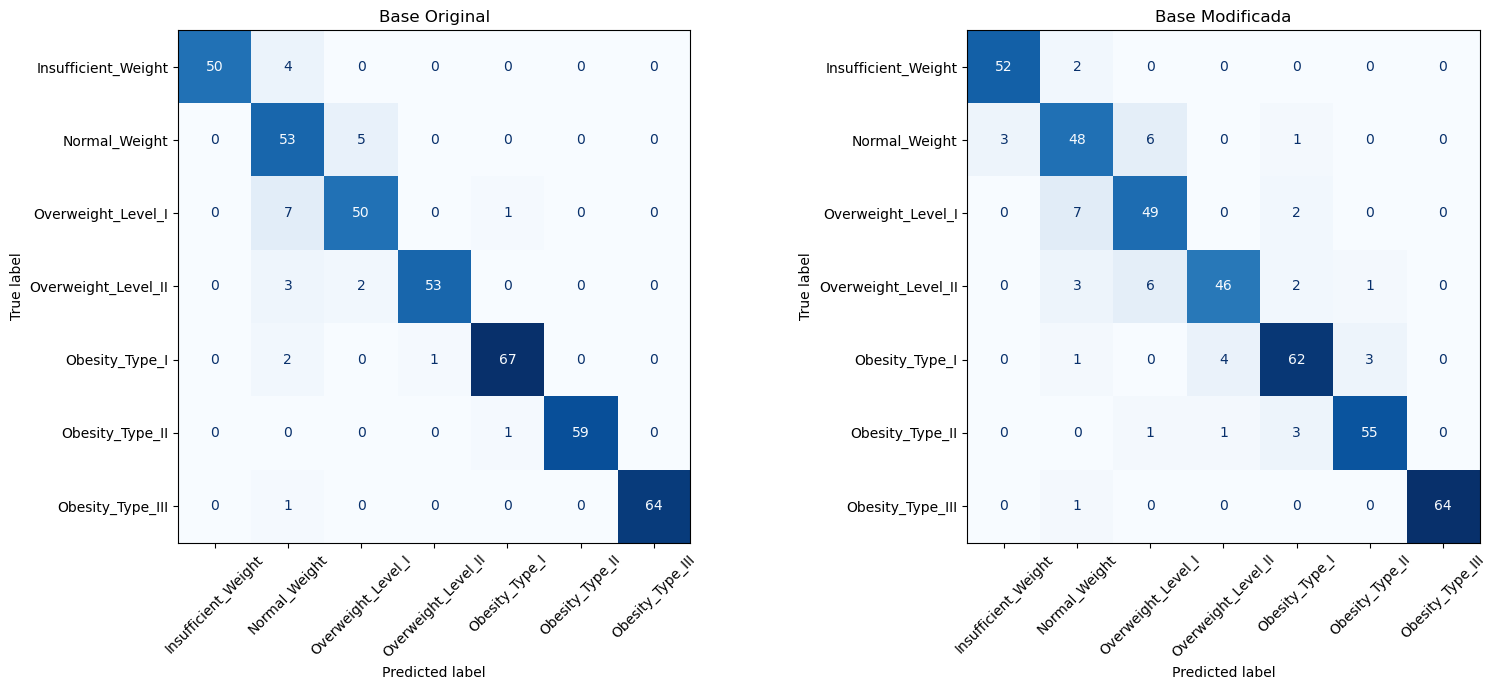

In [19]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 7))
for eixo, (nome, y_pred) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, y_pred, labels=ordem_classes, ax=eixo,
        cmap="Blues", xticks_rotation=45, colorbar=False,
    )
    eixo.set_title(f"Base {nome}")
plt.tight_layout()
plt.show()

#### Diferença no F1 macro

In [20]:
resumo = pd.DataFrame({
    nome: {"Acurácia": accuracy_score(y_teste, p),
           "F1 macro": f1_score(y_teste, p, average="macro")}
    for nome, p in previsoes.items()
}).T
display(resumo.round(4))
print("Diferença no F1 macro (Modificada − Original):",
      round(resumo.loc["Modificada", "F1 macro"] - resumo.loc["Original", "F1 macro"], 4))

,Acurácia,F1 macro
Original,0.9362,0.9362
Modificada,0.8889,0.8882


Diferença no F1 macro (Modificada − Original): -0.0481


In [21]:
f1_classes = pd.DataFrame({
    nome: pd.Series(f1_score(y_teste, p, labels=ordem_classes, average=None), index=ordem_classes)
    for nome, p in previsoes.items()
})
f1_classes["Diferença (Modificada − Original)"] = f1_classes["Modificada"] - f1_classes["Original"]
display(f1_classes.round(3))

,Original,Modificada,Diferença (Modificada − Original)
Insufficient_Weight,0.962,0.954,-0.007
Normal_Weight,0.828,0.800,-0.028
Overweight_Level_I,0.870,0.817,-0.053
Overweight_Level_II,0.946,0.844,-0.102
Obesity_Type_I,0.964,0.886,-0.078
Obesity_Type_II,0.992,0.924,-0.067
Obesity_Type_III,0.992,0.992,0.000


In [22]:
confusoes = []
for nome, p in previsoes.items():
    cm = confusion_matrix(y_teste, p, labels=ordem_classes)
    for i, real in enumerate(ordem_classes):
        for j, prevista in enumerate(ordem_classes):
            if i != j and cm[i, j] > 0:
                confusoes.append({"Base": nome, "Classe real": real,
                                  "Prevista como": prevista, "Quantidade": cm[i, j]})
confusoes = pd.DataFrame(confusoes)
display(confusoes.sort_values(["Base", "Quantidade"], ascending=[True, False])
        .groupby("Base").head(5))

,Base,Classe real,Prevista como,Quantidade
14,Modificada,Overweight_Level_I,Normal_Weight,7
12,Modificada,Normal_Weight,Overweight_Level_I,6
17,Modificada,Overweight_Level_II,Overweight_Level_I,6
21,Modificada,Obesity_Type_I,Overweight_Level_II,4
11,Modificada,Normal_Weight,Insufficient_Weight,3
2,Original,Overweight_Level_I,Normal_Weight,7
1,Original,Normal_Weight,Overweight_Level_I,5
0,Original,Insufficient_Weight,Normal_Weight,4
4,Original,Overweight_Level_II,Normal_Weight,3
5,Original,Overweight_Level_II,Overweight_Level_I,2


#### Análise Geral dos resultados da Floresta Aleatória

**Desempenho geral.** A base original obteve F1 macro de 0,936 no teste, contra 0,888
da base modificada, uma queda de aproximadamente 0,05 após a discretização de `Age` e
`Weight`. A acurácia seguiu o mesmo padrão (0,936 contra 0,889), o que equivale a cerca
de 20 erros a mais entre as 423 pessoas do teste.

**Classes mais confundidas.** Nas duas bases, a confusão mais frequente envolve
Normal_Weight e Overweight_Level_I: Overweight_Level_I foi previsto como Normal_Weight
7 vezes em ambas, e o sentido inverso ocorreu 5 vezes na original e 6 na modificada.
Essas duas classes já tinham os menores F1 na base original (0,828 e 0,870), ou seja,
são difíceis mesmo sem discretização. Na base modificada, aumentaram as confusões entre
classes mais altas: Overweight_Level_II previsto como Overweight_Level_I passou de 2 para
6 casos.

**Interpretação geral.** Quase todas as confusões ocorrem entre classes vizinhas, o que é
esperado, já que as classes são separadas por faixas contínuas de IMC e o erro tende a
ocorrer perto dos limites. As classes extremas foram pouco afetadas pela discretização
(Obesity_Type_III manteve F1 de 0,992 e Insufficient_Weight variou −0,007), o que sugere
que são mais fáceis de identificar por faixas amplas de peso. A maior perda ocorreu em
Overweight_Level_II (de 0,946 para 0,844).

## 3. Classificação com Perceptron de Múltiplas Camadas (MLP)

### 3.1 Preparação dos dados


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preparar_mlp(X_treino, X_teste):
    colunas_num = X_treino.select_dtypes(include="number").columns.tolist()
    colunas_cat = X_treino.select_dtypes(exclude="number").columns.tolist()

    transformador = ColumnTransformer(
        transformers=[
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colunas_cat),
            ("padronizacao", StandardScaler(), colunas_num),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_treino_t = transformador.fit_transform(X_treino)   # aprende média, desvio e categorias no treino
    X_teste_t = transformador.transform(X_teste)         # só aplica no teste
    return X_treino_t, X_teste_t, transformador


X_original_treino_mlp, X_original_teste_mlp, transf_original = preparar_mlp(
    X_original_treino, X_original_teste
)
X_modificado_treino_mlp, X_modificado_teste_mlp, transf_modificado = preparar_mlp(
    X_modificado_treino, X_modificado_teste
)

In [24]:
print("Original:  ", X_original_treino_mlp.shape, X_original_teste_mlp.shape)
print("Modificada:", X_modificado_treino_mlp.shape, X_modificado_teste_mlp.shape)

colunas_num = X_original_treino.select_dtypes(include="number").columns
display(X_original_treino_mlp[colunas_num].agg(["mean", "std"]).round(2))
display(X_original_teste_mlp[colunas_num].agg(["mean", "std"]).round(2))

Original:   (1688, 31) (423, 31)
Modificada: (1688, 35) (423, 35)


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
mean,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
mean,0.00,-0.00,0.01,-0.09,-0.02,-0.08,-0.06,0.03
std,0.96,0.97,1.03,1.04,1.02,1.00,1.02,1.07


### 3.2 Treinamento e testes de parâmetros




- **`hidden_layer_sizes`** — Define o número de neurônios em cada camada oculta. Foram testadas uma camada com 50 neurônios, uma com 100 e duas camadas com 100 e 50 neurônios.
- **`alpha`** — Controla a intensidade da regularização L2, que penaliza pesos elevados. Foram testados `0.0001`, `0.001`, `0.01` e `0.1`.
- **`max_iter=1000`** — Limita o treinamento a 1.000 iterações.
- **`random_state=42`** — Fixa a semente usada pelo modelo, inclusive na inicialização dos pesos.

In [25]:
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

bases_mlp = {
    "Original": (X_original_treino_mlp, X_original_teste_mlp),
    "Modificada": (X_modificado_treino_mlp, X_modificado_teste_mlp),
}

valores_camadas = [(50,), (100,), (100, 50)]
valores_alpha = [0.0001, 0.001, 0.01, 0.1]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados_mlp = []
parametros_mlp = {}   # guarda os parâmetros reais de cada configuração

for nome_base, (X_tr, X_te) in bases_mlp.items():
    for camadas in valores_camadas:
        for alpha in valores_alpha:
            config = f"hidden_layer_sizes={camadas}, alpha={alpha}"
            parametros_mlp[(nome_base, config)] = {"hidden_layer_sizes": camadas, "alpha": alpha}

            mlp = MLPClassifier(hidden_layer_sizes=camadas, alpha=alpha,
                                max_iter=1000, random_state=42)
            # Critério de escolha: validação cruzada só no treino
            f1_cv = cross_val_score(mlp, X_tr, y_treino, cv=cv,
                                    scoring="f1_macro", n_jobs=-1).mean()

            mlp.fit(X_tr, y_treino)
            pred_teste = mlp.predict(X_te)

            resultados_mlp.append({
                "Base": nome_base,
                "Configuração": config,
                "F1 macro (CV treino)": f1_cv,
                "Acurácia treino": mlp.score(X_tr, y_treino),
                "Acurácia teste": accuracy_score(y_teste, pred_teste),
                "F1 macro teste": f1_score(y_teste, pred_teste, average="macro"),
            })

resultados_mlp = pd.DataFrame(resultados_mlp)

c:\Users\Giovani\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Giovani\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Giovani\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [26]:
ordem = resultados_mlp.loc[resultados_mlp["Base"] == "Original", "Configuração"]

comparacao_mlp = (
    resultados_mlp.pivot(index="Configuração", columns="Base", values="F1 macro teste")
    .loc[ordem]
)
comparacao_mlp["Diferença (Modificada − Original)"] = (
    comparacao_mlp["Modificada"] - comparacao_mlp["Original"]
)
display(comparacao_mlp.round(4))

Base,Modificada,Original,Diferença (Modificada − Original)
Configuração,,,
"hidden_layer_sizes=(50,), alpha=0.0001",0.8463,0.9451,-0.0988
"hidden_layer_sizes=(50,), alpha=0.001",0.8508,0.9428,-0.0921
"hidden_layer_sizes=(50,), alpha=0.01",0.8385,0.9447,-0.1062
"hidden_layer_sizes=(50,), alpha=0.1",0.8437,0.9497,-0.1060
"hidden_layer_sizes=(100,), alpha=0.0001",0.8502,0.9300,-0.0798
"hidden_layer_sizes=(100,), alpha=0.001",0.8528,0.9299,-0.0771
"hidden_layer_sizes=(100,), alpha=0.01",0.8455,0.9275,-0.0820
"hidden_layer_sizes=(100,), alpha=0.1",0.8546,0.9492,-0.0946
"hidden_layer_sizes=(100, 50), alpha=0.0001",0.8417,0.9610,-0.1193


In [27]:
modelos_finais_mlp = {}
for nome_base, (X_tr, X_te) in bases_mlp.items():
    sub = resultados_mlp[resultados_mlp["Base"] == nome_base]
    melhor = sub.loc[sub["F1 macro (CV treino)"].idxmax(), "Configuração"]

    modelos_finais_mlp[nome_base] = MLPClassifier(
        **parametros_mlp[(nome_base, melhor)], max_iter=1000, random_state=42
    ).fit(X_tr, y_treino)

    print(f"{nome_base}: melhor configuração -> {melhor}")

Original: melhor configuração -> hidden_layer_sizes=(100, 50), alpha=0.1
Modificada: melhor configuração -> hidden_layer_sizes=(100,), alpha=0.01


### 3.3 Avaliação dos resultados

In [28]:
# Previsões de cada modelo final no teste
previsoes_mlp = {
    nome: modelos_finais_mlp[nome].predict(X_te)
    for nome, (X_tr, X_te) in bases_mlp.items()
}

# Relatório de classificação
for nome, y_pred in previsoes_mlp.items():
    print(f"===== MLP — Base {nome} =====")
    print(classification_report(y_teste, y_pred, labels=ordem_classes, digits=3))

===== MLP — Base Original =====
                     precision    recall  f1-score   support

Insufficient_Weight      0.982     1.000     0.991        54
      Normal_Weight      0.909     0.862     0.885        58
 Overweight_Level_I      0.867     0.897     0.881        58
Overweight_Level_II      0.983     0.983     0.983        58
     Obesity_Type_I      0.986     1.000     0.993        70
    Obesity_Type_II      0.983     0.983     0.983        60
   Obesity_Type_III      1.000     0.985     0.992        65

           accuracy                          0.960       423
          macro avg      0.959     0.958     0.958       423
       weighted avg      0.960     0.960     0.960       423

===== MLP — Base Modificada =====
                     precision    recall  f1-score   support

Insufficient_Weight      0.926     0.926     0.926        54
      Normal_Weight      0.772     0.759     0.765        58
 Overweight_Level_I      0.719     0.793     0.754        58
Overweight_Leve

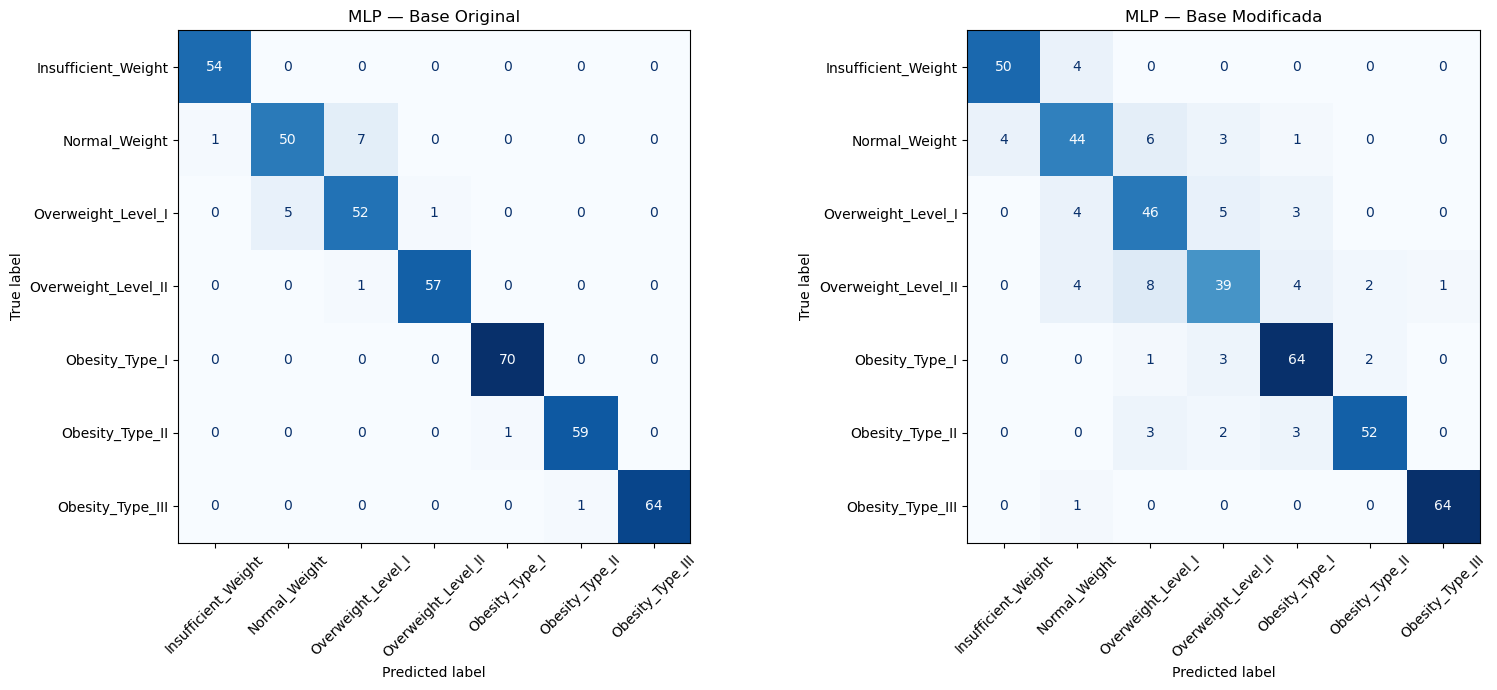

In [29]:
# Matrizes de confusão lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(16, 7))
for eixo, (nome, y_pred) in zip(eixos, previsoes_mlp.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, y_pred, labels=ordem_classes, ax=eixo,
        cmap="Blues", xticks_rotation=45, colorbar=False,
    )
    eixo.set_title(f"MLP — Base {nome}")
plt.tight_layout()
plt.show()

In [30]:
# Acurácia e F1 macro, com a diferença entre as bases
resumo_mlp = pd.DataFrame({
    nome: {"Acurácia": accuracy_score(y_teste, p),
           "F1 macro": f1_score(y_teste, p, average="macro")}
    for nome, p in previsoes_mlp.items()
}).T
display(resumo_mlp.round(4))
print("Diferença no F1 macro (Modificada − Original):",
      round(resumo_mlp.loc["Modificada", "F1 macro"] - resumo_mlp.loc["Original", "F1 macro"], 4))

# F1 por classe: mostra onde a discretização afetou o MLP
f1_classes_mlp = pd.DataFrame({
    nome: pd.Series(f1_score(y_teste, p, labels=ordem_classes, average=None), index=ordem_classes)
    for nome, p in previsoes_mlp.items()
})
f1_classes_mlp["Diferença (Modificada − Original)"] = (
    f1_classes_mlp["Modificada"] - f1_classes_mlp["Original"]
)
display(f1_classes_mlp.round(3))

,Acurácia,F1 macro
Original,0.9598,0.9583
Modificada,0.8487,0.8455


Diferença no F1 macro (Modificada − Original): -0.1129


,Original,Modificada,Diferença (Modificada − Original)
Insufficient_Weight,0.991,0.926,-0.065
Normal_Weight,0.885,0.765,-0.120
Overweight_Level_I,0.881,0.754,-0.127
Overweight_Level_II,0.983,0.709,-0.274
Obesity_Type_I,0.993,0.883,-0.110
Obesity_Type_II,0.983,0.897,-0.087
Obesity_Type_III,0.992,0.985,-0.008


#### Análise dos resultados do MLP

**Teste de parâmetros.** A base original superou a modificada em todas as 12
configurações testadas, com diferença no F1 macro do teste entre 0,077 e 0,119. As
variações entre configurações da mesma base foram pequenas diante dessa diferença
(cerca de 0,03 na original e 0,03 na modificada), o que indica que o efeito vem da
discretização e não da escolha de parâmetros.

**Convergência.** Alguns treinamentos atingiram o limite de 1.000 iterações antes de satisfazer o critério de convergência. As métricas dessas execuções correspondem ao modelo obtido ao atingir esse limite.

**Desempenho geral.** Com a melhor configuração de cada base, o F1 macro foi de 0,958
na original e 0,845 na modificada, uma queda de 0,113. A acurácia seguiu o mesmo
padrão (0,960 contra 0,849).

**Desempenho por classe.** A discretização piorou o F1 de todas as classes. A maior
perda ocorreu em Overweight_Level_II (de 0,983 para 0,709), seguida de Overweight_Level_I
(−0,127), Normal_Weight (−0,120) e Obesity_Type_I (−0,110). Apenas Obesity_Type_III
permaneceu praticamente estável (−0,008).

**Confusões.** Na base original, quase todos os 17 erros ocorrem entre classes
vizinhas. Na base modificada, os 64 erros se distribuem por mais classes, incluindo
confusões não adjacentes, como Overweight_Level_II previsto como Normal_Weight.

**Comparação com a Floresta Aleatória.** A queda do MLP (−0,113) foi bem maior que a da
Floresta (−0,048). Com os dados originais o MLP foi melhor (0,958 contra 0,936), mas com
os dados discretizados ficou abaixo (0,845 contra 0,888). Isso sugere que o MLP é mais
sensível à perda de informação contínua de idade e peso.

## 4. Agrupamento com K-médias

### 4.1 Preparação dos dados


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Prepara a base completa (sem a variável-alvo) codificando categorias e padronizando números
def preparar_kmeans(X):
    colunas_num = X.select_dtypes(include="number").columns.tolist()
    colunas_cat = X.select_dtypes(exclude="number").columns.tolist()

    transformador = ColumnTransformer(
        transformers=[
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colunas_cat),
            ("padronizacao", StandardScaler(), colunas_num),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_t = transformador.fit_transform(X)
    return X_t, transformador


X_original_kmeans, transf_original_kmeans = preparar_kmeans(X_original)
X_modificado_kmeans, transf_modificado_kmeans = preparar_kmeans(X_modificado)

In [32]:
print("Original:  ", X_original_kmeans.shape)
print("Modificada:", X_modificado_kmeans.shape)

colunas_num_orig = X_original.select_dtypes(include="number").columns
colunas_num_mod = X_modificado.select_dtypes(include="number").columns

print("\nMédia e desvio-padrão das colunas numéricas (Base Original):")
display(X_original_kmeans[colunas_num_orig].agg(["mean", "std"]).round(2))

print("Média e desvio-padrão das colunas numéricas (Base Modificada):")
display(X_modificado_kmeans[colunas_num_mod].agg(["mean", "std"]).round(2))

Original:   (2111, 31)
Modificada: (2111, 35)

Média e desvio-padrão das colunas numéricas (Base Original):


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
mean,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Média e desvio-padrão das colunas numéricas (Base Modificada):


,Height,FCVC,NCP,CH2O,FAF,TUE
mean,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


### 4.2 Execução e testes de parâmetros

#### Parâmetros da implementação (`KMeans`)
- **`n_clusters` (`k`)**: quantidade de grupos (clusters) e de centroides que o algoritmo irá formar. Testamos valores de `2` a `10` nas duas bases (incluindo `k = 7`, que corresponde às 7 classes reais de `NObeyesdad`).
- **`init`**: método de inicialização dos centroides. Testamos `'k-means++'` (seleciona centroides iniciais afastados entre si para acelerar a convergência e reduzir o risco de mínimos locais ruins) e `'random'` (escolhe `k` observações aleatórias da base como centroides iniciais).
- **`n_init`**: número de vezes que o K-médias é executado com diferentes sementes de centroides iniciais (`n_init=10`), mantendo ao final a partição de menor inércia.
- **`max_iter`**: número máximo de iterações permitidas em uma única execução do algoritmo (`max_iter=300`).
- **`tol`**: tolerância relativa na variação dos centroides entre duas iterações consecutivas para declarar convergência (`tol=1e-4`).
- **`random_state`**: semente do gerador pseudoaleatório (`random_state=42`), garantindo reprodutibilidade dos resultados.

In [33]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

bases_kmeans = {
    "Original": X_original_kmeans,
    "Modificada": X_modificado_kmeans,
}

valores_k = [2, 3, 4, 5, 6, 7, 8, 9, 10]
valores_init = ["k-means++", "random"]

resultados_kmeans = []
parametros_kmeans = {}
modelos_kmeans = {}

for nome_base, X_km in bases_kmeans.items():
    for init_metodo in valores_init:
        for k in valores_k:
            config = f"n_clusters={k}, init={init_metodo}"
            parametros_kmeans[(nome_base, config)] = {"n_clusters": k, "init": init_metodo}

            km = KMeans(
                n_clusters=k,
                init=init_metodo,
                n_init=10,
                max_iter=300,
                random_state=42,
            )
            rotulos = km.fit_predict(X_km)
            silhueta = silhouette_score(X_km, rotulos)

            modelos_kmeans[(nome_base, k, init_metodo)] = km
            resultados_kmeans.append({
                "Base": nome_base,
                "k": k,
                "init": init_metodo,
                "Configuração": config,
                "Índice de Silhueta": silhueta,
                "Inércia": km.inertia_,
            })

resultados_kmeans = pd.DataFrame(resultados_kmeans)

c:\Users\Giovani\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Giovani\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Giovani\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Giovani\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Giovani\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid

In [34]:
# Ordem original dos testes
ordem_km = resultados_kmeans.loc[resultados_kmeans["Base"] == "Original", "Configuração"]

# Tabela comparativa do Índice de Silhueta para todas as configurações testadas
comparacao_kmeans_completa = (
    resultados_kmeans.pivot(index="Configuração", columns="Base", values="Índice de Silhueta")
    .loc[ordem_km]
)
comparacao_kmeans_completa["Diferença (Modificada − Original)"] = (
    comparacao_kmeans_completa["Modificada"] - comparacao_kmeans_completa["Original"]
)

display(comparacao_kmeans_completa.round(4))

Base,Modificada,Original,Diferença (Modificada − Original)
Configuração,,,
"n_clusters=2, init=k-means++",0.1351,0.1277,0.0074
"n_clusters=3, init=k-means++",0.1314,0.1233,0.0081
"n_clusters=4, init=k-means++",0.1214,0.1339,-0.0125
"n_clusters=5, init=k-means++",0.1227,0.1383,-0.0156
"n_clusters=6, init=k-means++",0.1177,0.1473,-0.0295
"n_clusters=7, init=k-means++",0.1235,0.1509,-0.0274
"n_clusters=8, init=k-means++",0.1190,0.1388,-0.0198
"n_clusters=9, init=k-means++",0.1194,0.1471,-0.0276
"n_clusters=10, init=k-means++",0.1272,0.1436,-0.0164


### 4.3 Avaliação dos agrupamentos


In [35]:
# Comparação direta por valor de k usando a inicialização padrão (k-means++)
resultados_kmeans_padrao = resultados_kmeans[resultados_kmeans["init"] == "k-means++"].copy()

comparacao_kmeans = resultados_kmeans_padrao.pivot(
    index="k", columns="Base", values="Índice de Silhueta"
)[["Original", "Modificada"]]
comparacao_kmeans["Diferença (Modificada − Original)"] = (
    comparacao_kmeans["Modificada"] - comparacao_kmeans["Original"]
)

display(comparacao_kmeans.round(4))

# Identifica o melhor k de cada base
modelos_finais_kmeans = {}
for nome_base in ["Original", "Modificada"]:
    sub = resultados_kmeans_padrao[resultados_kmeans_padrao["Base"] == nome_base]
    linha_melhor = sub.loc[sub["Índice de Silhueta"].idxmax()]
    melhor_k = int(linha_melhor["k"])
    melhor_sil = linha_melhor["Índice de Silhueta"]
    modelos_finais_kmeans[nome_base] = modelos_kmeans[(nome_base, melhor_k, "k-means++")]
    print(f"{nome_base} - melhor k: {melhor_k} (Índice de Silhueta = {melhor_sil:.4f})")

Base,Original,Modificada,Diferença (Modificada − Original)
k,,,
2,0.1277,0.1351,0.0074
3,0.1233,0.1314,0.0081
4,0.1339,0.1214,-0.0125
5,0.1383,0.1227,-0.0156
6,0.1473,0.1177,-0.0295
7,0.1509,0.1235,-0.0274
8,0.1388,0.1190,-0.0198
9,0.1471,0.1194,-0.0276
10,0.1436,0.1272,-0.0164


Original - melhor k: 7 (Índice de Silhueta = 0.1509)
Modificada - melhor k: 2 (Índice de Silhueta = 0.1351)


In [36]:
# Top 5 configurações de cada base ordenadas pelo Índice de Silhueta
display(
    resultados_kmeans.sort_values(["Base", "Índice de Silhueta"], ascending=[True, False])
    .groupby("Base").head(5)[["Base", "Configuração", "k", "init", "Índice de Silhueta", "Inércia"]]
    .round({"Índice de Silhueta": 4, "Inércia": 1})
)

,Base,Configuração,k,init,Índice de Silhueta,Inércia
18,Modificada,"n_clusters=2, init=k-means++",2,k-means++,0.1351,16821.5
27,Modificada,"n_clusters=2, init=random",2,random,0.1351,16821.5
34,Modificada,"n_clusters=9, init=random",9,random,0.1339,11705.6
35,Modificada,"n_clusters=10, init=random",10,random,0.1327,11286.6
28,Modificada,"n_clusters=3, init=random",3,random,0.1316,15479.1
14,Original,"n_clusters=7, init=random",7,random,0.1511,13019.2
5,Original,"n_clusters=7, init=k-means++",7,k-means++,0.1509,13019.0
17,Original,"n_clusters=10, init=random",10,random,0.1491,11743.4
13,Original,"n_clusters=6, init=random",6,random,0.1474,13631.7
4,Original,"n_clusters=6, init=k-means++",6,k-means++,0.1473,13631.7


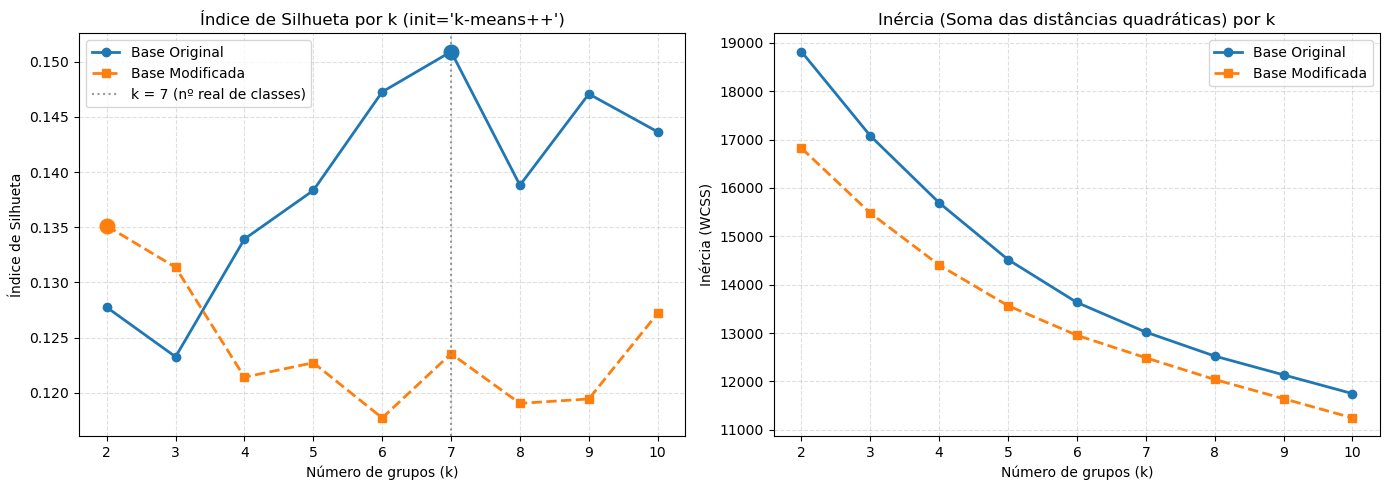

In [37]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Índice de Silhueta por k
for nome_base, estilo, cor in [("Original", "-o", "#1f77b4"), ("Modificada", "--s", "#ff7f0e")]:
    sub = resultados_kmeans_padrao[resultados_kmeans_padrao["Base"] == nome_base]
    eixos[0].plot(sub["k"], sub["Índice de Silhueta"], estilo, color=cor, linewidth=2, label=f"Base {nome_base}")
    melhor_linha = sub.loc[sub["Índice de Silhueta"].idxmax()]
    eixos[0].scatter(melhor_linha["k"], melhor_linha["Índice de Silhueta"], color=cor, s=110, zorder=5)

eixos[0].axvline(7, color="gray", linestyle=":", alpha=0.8, label="k = 7 (nº real de classes)")
eixos[0].set_title("Índice de Silhueta por k (init='k-means++')")
eixos[0].set_xlabel("Número de grupos (k)")
eixos[0].set_ylabel("Índice de Silhueta")
eixos[0].set_xticks(valores_k)
eixos[0].grid(True, linestyle="--", alpha=0.4)
eixos[0].legend()

# Gráfico 2: Inércia (WCSS) por k
for nome_base, estilo, cor in [("Original", "-o", "#1f77b4"), ("Modificada", "--s", "#ff7f0e")]:
    sub = resultados_kmeans_padrao[resultados_kmeans_padrao["Base"] == nome_base]
    eixos[1].plot(sub["k"], sub["Inércia"], estilo, color=cor, linewidth=2, label=f"Base {nome_base}")

eixos[1].set_title("Inércia (Soma das distâncias quadráticas) por k")
eixos[1].set_xlabel("Número de grupos (k)")
eixos[1].set_ylabel("Inércia (WCSS)")
eixos[1].set_xticks(valores_k)
eixos[1].grid(True, linestyle="--", alpha=0.4)
eixos[1].legend()

plt.tight_layout()
plt.show()

In [38]:
# Quantidade de registros por grupo em k = 7 (número real de categorias de obesidade)
dist_k7 = pd.DataFrame({
    nome_base: pd.Series(modelos_kmeans[(nome_base, 7, "k-means++")].labels_).value_counts().sort_index()
    for nome_base in ["Original", "Modificada"]
})
dist_k7.index.name = "Grupo (cluster)"
print("Quantidade de indivíduos em cada grupo para k = 7:")
display(dist_k7.T)

Quantidade de indivíduos em cada grupo para k = 7:


Grupo (cluster),0,1,2,3,4,5,6
Original,262,270,279,282,333,283,402
Modificada,350,263,359,305,192,434,208


#### Análise dos resultados do K-médias

**Efeito geral da discretização.** A substituição dos valores contínuos de `Age` e `Weight` por faixas categóricas alterou o comportamento dos agrupamentos e reduziu o Índice de Silhueta em praticamente toda a faixa de valores testados (`k = 4` até `k = 10`). Apenas em divisões muito amplas (`k = 2` e `k = 3`) a base modificada teve silhueta ligeiramente maior (`+0,0074` em `k = 2` e `+0,0081` em `k = 3`), pois as três faixas discretas de peso (`Leve`, `Normal`, `Pesado`) e idade criam blocos binários que favorecem uma partição grosseira em 2 ou 3 grandes grupos.

**Melhor `k` em cada base.** Na base original, o Índice de Silhueta cresce de forma consistente à medida que `k` aumenta até atingir o pico exatamente em **`k = 7` (`0,1509` com `k-means++` e `0,1511` com `random`)**, valor que coincide com as 7 categorias reais de nível de obesidade (`NObeyesdad`). Já na base modificada, o melhor valor cai para **`k = 2` (`0,1351`)**, e em **`k = 7`** a silhueta recua para **`0,1235`** (queda de `-0,0274`, ou `-18,2%` em relação à base original).

**Teste dos parâmetros (`n_clusters` e `init`).** As duas estratégias de inicialização (`'k-means++'` e `'random'` com `n_init=10`) produziram curvas bastante próximas e confirmaram o mesmo padrão: a base original supera a modificada em todas as configurações com `k >= 4` (com diferenças chegando a `-0,0295` em `k = 6` com `k-means++` e `-0,0367` em `k = 7` com `random`). Isso mostra que a perda de qualidade nos agrupamentos mais granulares decorre da discretização dos dados, e não da escolha de inicialização.

**Interpretação geométrica.** Os valores absolutos de silhueta (em torno de `0,12` a `0,15`) são típicos de bases com dezenas de colunas binárias geradas por *One-Hot Encoding* (31 colunas na original e 35 na modificada), onde a distância euclidiana se espalha em alta dimensão. Na base original, as variáveis contínuas padronizadas `Weight` e `Age` preservam gradientes suaves de distância que permitem ao K-médias separar melhor os 7 perfis corporais. Quando `Weight` e `Age` são discretizados em apenas 3 faixas cada, indivíduos com pesos bastante distintos (por exemplo, `81 kg` e `130 kg`, ambos classificados como `Pesado`) passam a ter distância zero nesse atributo, reduzindo a separabilidade entre grupos intermediários e elevados.

## 5. Comparação dos resultados e conclusão

### 5.1 Comparação dos classificadores


In [39]:
# Tabela única com acurácia e F1 macro (teste) dos dois classificadores nas duas bases
comparacao_modelos = pd.concat(
    {
        "Floresta Aleatória": resumo,
        "MLP": resumo_mlp,
    },
    names=["Modelo", "Base"],
).reset_index()

tabela_modelos = comparacao_modelos.pivot(index="Modelo", columns="Base", values=["Acurácia", "F1 macro"])
for metrica in ["Acurácia", "F1 macro"]:
    tabela_modelos[(metrica, "Diferença")] = (
        tabela_modelos[(metrica, "Modificada")] - tabela_modelos[(metrica, "Original")]
    )
tabela_modelos = tabela_modelos[[
    ("Acurácia", "Original"), ("Acurácia", "Modificada"), ("Acurácia", "Diferença"),
    ("F1 macro", "Original"), ("F1 macro", "Modificada"), ("F1 macro", "Diferença"),
]]
display(tabela_modelos.round(4))

Acurácia                      F1 macro                     
Base               Original Modificada Diferença Original Modificada Diferença
Modelo                                                                        
Floresta Aleatória   0.9362     0.8889   -0.0473   0.9362     0.8882   -0.0481
MLP                  0.9598     0.8487   -0.1111   0.9583     0.8455   -0.1129

,Floresta Aleatória,MLP
Insufficient_Weight,-0.007,-0.065
Normal_Weight,-0.028,-0.120
Overweight_Level_I,-0.053,-0.127
Overweight_Level_II,-0.102,-0.274
Obesity_Type_I,-0.078,-0.110
Obesity_Type_II,-0.067,-0.087
Obesity_Type_III,0.000,-0.008


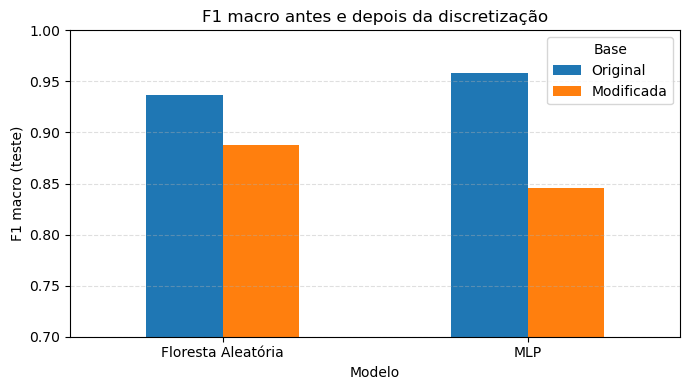

In [40]:
# Diferença do F1 por classe nos dois modelos (Modificada − Original)
queda_por_classe = pd.DataFrame({
    "Floresta Aleatória": f1_classes["Diferença (Modificada − Original)"],
    "MLP": f1_classes_mlp["Diferença (Modificada − Original)"],
})
display(queda_por_classe.round(3))

# Gráfico comparando o F1 macro de cada modelo nas duas bases
ax = comparacao_modelos.pivot(index="Modelo", columns="Base", values="F1 macro")[["Original", "Modificada"]].plot(
    kind="bar", figsize=(7, 4), rot=0, color=["#1f77b4", "#ff7f0e"]
)
ax.set_ylabel("F1 macro (teste)")
ax.set_ylim(0.7, 1.0)
ax.set_title("F1 macro antes e depois da discretização")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### Análise da comparação dos classificadores

**Antes da discretização.** Com os dados originais, o MLP foi o melhor modelo (acurácia 0,960 e F1 macro 0,958), à frente da Floresta Aleatória (0,936 em ambas as métricas). A diferença de cerca de 0,02 é pequena, mas favorece o MLP, que tende a aproveitar bem as variáveis contínuas padronizadas, em especial `Weight` e `Height`, que definem o IMC e, portanto, a classe.

**Depois da discretização.** Os dois modelos pioraram. A Floresta caiu de 0,936 para 0,888 no F1 macro (−0,048), enquanto o MLP caiu de 0,958 para 0,845 (−0,113), uma queda mais de duas vezes maior. A ordem se inverteu: na base modificada a Floresta (0,888) superou o MLP (0,845) por cerca de 0,04.

**Por classe.** A discretização prejudicou todas as classes nos dois modelos, exceto `Obesity_Type_III`, que ficou praticamente estável (0,000 na Floresta e −0,008 no MLP) por ser identificável com faixas amplas de peso. A maior perda foi em `Overweight_Level_II` nos dois modelos (−0,102 na Floresta e −0,274 no MLP). As classes intermediárias (`Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`) concentram as maiores perdas, pois dependem de diferenças finas de peso que três faixas não representam.

**Principais diferenças entre os classificadores.** A Floresta Aleatória usa cortes por variável e pode compensar parte da informação perdida combinando `Height` (que continuou contínua) com as demais variáveis, o que sugere maior robustez à discretização. O MLP depende de entradas numéricas; ao trocar `Weight` e `Age` por colunas binárias, perde o gradiente contínuo que explorava bem e sofre mais. Com dados contínuos, porém, o MLP foi superior.

### 5.2 Comparação dos agrupamentos

In [41]:
# Resumo do K-médias (init='k-means++'): silhueta por k nas duas bases e melhor k de cada uma
resumo_kmeans = comparacao_kmeans.copy()
resumo_kmeans["Base com maior silhueta"] = resumo_kmeans.apply(
    lambda linha: "Modificada" if linha["Modificada"] > linha["Original"] else "Original", axis=1
)
display(resumo_kmeans.round(4))

melhores = (
    resultados_kmeans_padrao.loc[resultados_kmeans_padrao.groupby("Base")["Índice de Silhueta"].idxmax()]
    [["Base", "k", "Índice de Silhueta"]].set_index("Base")
)
display(melhores.round(4))

k7 = comparacao_kmeans.loc[7]
print(f"Silhueta em k = 7: Original = {k7['Original']:.4f} | Modificada = {k7['Modificada']:.4f} "
      f"| variação relativa = {(k7['Modificada'] / k7['Original'] - 1) * 100:.1f}%")

Base,Original,Modificada,Diferença (Modificada − Original),Base com maior silhueta
k,,,,
2,0.1277,0.1351,0.0074,Modificada
3,0.1233,0.1314,0.0081,Modificada
4,0.1339,0.1214,-0.0125,Original
5,0.1383,0.1227,-0.0156,Original
6,0.1473,0.1177,-0.0295,Original
7,0.1509,0.1235,-0.0274,Original
8,0.1388,0.1190,-0.0198,Original
9,0.1471,0.1194,-0.0276,Original
10,0.1436,0.1272,-0.0164,Original


,k,Índice de Silhueta
Base,,
Modificada,2,0.1351
Original,7,0.1509


Silhueta em k = 7: Original = 0.1509 | Modificada = 0.1235 | variação relativa = -18.1%


#### Análise da comparação dos agrupamentos

**Melhor `k`.** Com a inicialização `k-means++`, a maior silhueta foi de 0,1509 em `k = 7` na base original e de 0,1351 em `k = 2` na modificada. Para o mesmo `k = 7`, a silhueta passou de 0,1509 para 0,1235. Embora o melhor `k` na base original coincida com o número de classes de obesidade, a silhueta mede a separação dos grupos com base nos atributos de entrada. Verificar a correspondência entre os grupos e as classes exigiria uma análise adicional.

**Separação dos grupos.** Para `k ≥ 4` a base original teve silhueta maior em todos os valores testados (diferenças de −0,013 a −0,030 para a modificada). Apenas em `k = 2` (+0,0074) e `k = 3` (+0,0081) a base modificada ficou ligeiramente acima, o que é compatível com as faixas criando blocos grosseiros que favorecem partições em poucos grupos. As duas inicializações (`k-means++` e `random`) levaram à mesma conclusão.

**Ressalva.** Todos os valores de silhueta são baixos (entre 0,11 e 0,15), indicando grupos pouco separados em ambas as bases, o que é esperado com dezenas de colunas binárias geradas por *One-Hot Encoding*. As diferenças entre as bases são pequenas em valor absoluto, mas se repetem em toda a faixa `k ≥ 4`.

### 5.3 Conclusão

**Resumo dos resultados**

| Modelo | Métrica | Original | Modificada | Efeito da discretização |
|---|---|---|---|---|
| Floresta Aleatória | F1 macro | 0,936 | 0,888 | Piorou (−0,048) |
| MLP | F1 macro | 0,958 | 0,845 | Piorou bastante (−0,113) |
| K-médias | Silhueta no melhor `k` | 0,151 (`k = 7`) | 0,135 (`k = 2`) | Piorou e mudou o melhor `k` |
| K-médias | Silhueta em `k = 2` e `k = 3` | 0,128 e 0,123 | 0,135 e 0,131 | Melhorou pouco (+0,007 e +0,008) |

**Conclusão.** Nos valores obtidos, a discretização de `Age` e `Weight` não melhorou nenhum modelo de forma relevante.

- **Piorou:** os dois classificadores. A Floresta Aleatória perdeu cerca de 0,05 de F1 macro e o MLP cerca de 0,11, passando de melhor a pior classificador. Entre as classes, sofreram mais as de peso normal e sobrepeso. O K-médias também piorou para `k ≥ 4`, e o `k` de maior silhueta deixou de ser 7 e passou a ser 2.
- **Pouco alterou:** a classe `Obesity_Type_III` nos dois classificadores (F1 entre 0,985 e 0,992) e o K-médias com poucos grupos (`k = 2` e `k = 3`), em que a silhueta subiu cerca de 0,01.

Uma explicação plausível é que `Weight`, junto com `Height`, determina o IMC e a classe; ao reduzi-la a três faixas, pessoas de pesos bem diferentes passam a ser tratadas como iguais e a informação perdida não é recuperada pelas demais variáveis. Para esta base, portanto, parece preferível manter `Age` e `Weight` contínuas.

**Limitações.** Os resultados vêm de uma única divisão treino/teste (423 registros) e de uma semente fixa. Além disso, 77% da base é sintética (SMOTE), o que pode tornar as métricas absolutas otimistas. O sentido do efeito é claro, mas diferenças pequenas (como em `k = 2` e `k = 3` no K-médias) devem ser interpretadas com cautela.